In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Path to your dataset
dataset_path = '/content/drive/MyDrive/Micro_Expressions'

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [3]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

In [4]:
train_generator = datagen.flow_from_directory(
    '/content/drive/MyDrive/Micro_Expressions/train', # Adjust path if needed
    target_size=(48, 48), # Standard size for facial expressions
    color_mode='grayscale', # Usually better for expressions
    batch_size=64,
    class_mode='categorical',
    subset='training'
)

Found 6083 images belonging to 7 classes.


In [5]:
validation_generator = datagen.flow_from_directory(
    '/content/drive/MyDrive/Micro_Expressions/train',
    target_size=(48, 48),
    color_mode='grayscale',
    batch_size=64,
    class_mode='categorical',
    subset='validation'
)

Found 1517 images belonging to 7 classes.


In [6]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(48, 48, 1)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5), # Prevents overfitting
    Dense(train_generator.num_classes, activation='softmax') # Output layer
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [8]:
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=validation_generator,
    steps_per_epoch=train_generator.samples // 64,
    validation_steps=validation_generator.samples // 64
)

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1806s 19s/step - accuracy: 0.3190 - loss: 1.7435 - val_accuracy: 0.4701 - val_loss: 1.4818
Epoch 2/15
 1/95 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.3750 - loss: 1.5967

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 139ms/step - accuracy: 0.3750 - loss: 1.5967 - val_accuracy: 0.4640 - val_loss: 1.4980
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 431ms/step - accuracy: 0.4634 - loss: 1.4739 - val_accuracy: 0.4552 - val_loss: 1.4229
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.4219 - loss: 1.4628 - val_accuracy: 0.4688 - val_loss: 1.4094
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 70s 354ms/step - accuracy: 0.4948 - loss: 1.3758 - val_accuracy: 0.5374 - val_loss: 1.2967
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.4219 - loss: 1.5548 - val_accuracy: 0.5346 - val_loss: 1.2935
Epoch 7/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 35s 362ms/step - accuracy: 0.5408 - loss: 1.2604 - val_accuracy: 0.5469 - val_loss: 1.2331
Epoch 8/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.4844 - loss: 1.3365 - val_accuracy: 0.5469 - val_loss: 1.2279
Epoch 9/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 41s 434ms/step - accuracy: 0.5640 - loss: 1.1912 - val_accuracy: 0.5802 - va

In [9]:
try:
    test_datagen = ImageDataGenerator(rescale=1./255)
    test_generator = test_datagen.flow_from_directory(
        '/content/drive/MyDrive/Micro_Expressions/test',
        target_size=(48, 48),
        color_mode='grayscale',
        batch_size=64,
        class_mode='categorical'
    )
    test_loss, test_acc = model.evaluate(test_generator)
    print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
except Exception as e:
    print("\nNo separate 'test' folder found, skipping final test evaluation.")

Found 1860 images belonging to 7 classes.
30/30 ━━━━━━━━━━━━━━━━━━━━ 443s 15s/step - accuracy: 0.6462 - loss: 1.0101

Test Accuracy: 64.62%


In [10]:
model.save('/content/drive/MyDrive/facial_expression_model.h5')
print("Model training complete and saved to Drive!")

Model training complete and saved to Drive!


In [11]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2

def video_stream():
  js = Javascript('''var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;

    // JavaScript to access webcam and display it
    async function startVideo() {
        div = document.createElement('div');
        document.body.appendChild(div);
        video = document.createElement('video');
        video.style.display = 'block';
        video.width = 400;
        video.height = 300;
        video.autoplay = true;
        video.muted = true;
        stream = await navigator.mediaDevices.getUserMedia({video: true});
        video.srcObject = stream;
        div.appendChild(video);

        // Wait for video to load metadata to get actual dimensions
        await new Promise((resolve) => {
            video.onloadedmetadata = () => {
                captureCanvas = document.createElement('canvas');
                captureCanvas.width = video.videoWidth;
                captureCanvas.height = video.videoHeight;
                resolve();
            };
        });
        return true;
    }

    async function takePhoto() {
        captureCanvas.getContext('2d').drawImage(video, 0, 0);
        return captureCanvas.toDataURL('image/jpeg');
    }
  ''')
  display(js)

def js_to_image(js_reply):
    # Convert base64 image data to OpenCV format
    image_bytes = b64decode(js_reply.split(',')[1])
    # Use numpy/cv2 to convert bytes to array
    nparr = np.frombuffer(image_bytes, np.uint8)
    image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    return image

In [24]:
import os
import cv2

cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
if os.path.exists(cascade_path):
    print(f"Cascade file found at: {cascade_path}")
else:
    print(f"Cascade file NOT found at: {cascade_path}")
    print("This might mean the `haarcascades` data is missing from your OpenCV installation.")

Cascade file found at: /usr/local/lib/python3.13/dist-packages/cv2/data/haarcascade_frontalface_default.xml


In [14]:
import sys
!{sys.executable} -m pip install dlib

Now that `dlib` is installed, I will modify the previous cell to use `dlib` for face detection.

Detected Expression Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Starting live camera inference... Press the Stop button in Colab to end.


<IPython.core.display.Javascript object>

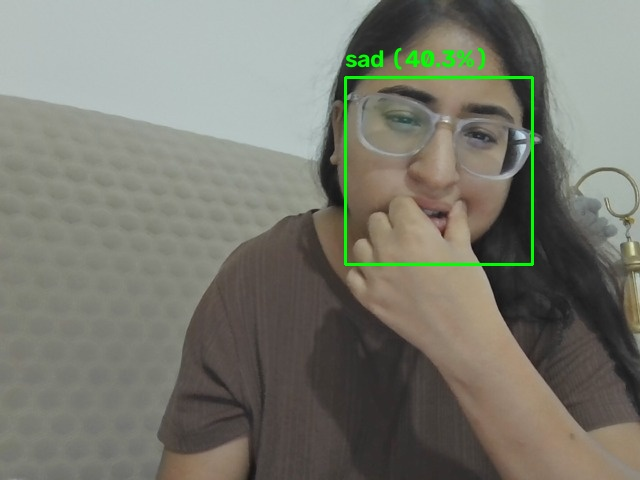

Stream stopped by user.


In [19]:
import cv2
import numpy as np
import dlib # Import dlib for face detection
from google.colab.output import eval_js
from IPython.display import display, Image
import os

# Initialize dlib's face detector
detector = dlib.get_frontal_face_detector()

# Define your emotion class labels
class_labels = sorted(os.listdir('/content/drive/MyDrive/Micro_Expressions/train'))
print("Detected Expression Classes:", class_labels)
print("Starting live camera inference... Press the Stop button in Colab to end.")

# Start the raw background video feed
video_stream()
eval_js('startVideo()', ignore_result=True)

# Create a display handle for smooth, flicker-free image updating
display_handle = display(display_id=True)

try:
    while True:
        js_reply = eval_js('takePhoto()')
        if not js_reply:
            continue

        frame = js_to_image(js_reply)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Detect faces using dlib
        # The '1' means to upsample the image 1 time, which can help detect smaller faces
        faces = detector(gray, 1)

        for face in faces:
            # dlib.rectangle object provides coordinates
            x, y, w, h = face.left(), face.top(), face.width(), face.height()

            # Draw rectangle around the face
            cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

            # Crop, resize, and normalize for the model
            roi_gray = gray[y:y + h, x:x + w]
            roi_resized = cv2.resize(roi_gray, (48, 48), interpolation=cv2.INTER_AREA)
            roi_normalized = roi_resized.astype('float32') / 255.0
            roi_reshaped = np.expand_dims(roi_normalized, axis=0)
            roi_reshaped = np.expand_dims(roi_reshaped, axis=-1)

            # Predict the expression
            prediction = model.predict(roi_reshaped, verbose=0)
            max_index = int(np.argmax(prediction))
            predicted_emotion = class_labels[max_index]
            confidence = float(np.max(prediction)) * 100

            # Put text label above the rectangle
            label = f"{predicted_emotion} ({confidence:.1f}%)"
            cv2.putText(frame, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        # Convert the processed OpenCV frame to a JPEG and push it to the display handle
        _, jpeg = cv2.imencode('.jpg', frame)
        display_handle.update(Image(data=jpeg.tobytes()))

except KeyboardInterrupt:
    print("Stream stopped by user.")

In [18]:
import cv2
print(cv2.__version__)

5.0.0


In [20]:
import cv2
if hasattr(cv2, 'CascadeClassifier'):
    print("cv2.CascadeClassifier is available.")
else:
    print("cv2.CascadeClassifier is NOT available. This indicates an issue with the OpenCV installation or a corrupted environment.")

cv2.CascadeClassifier is NOT available. This indicates an issue with the OpenCV installation or a corrupted environment.


In [21]:
import os
import cv2

cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
if os.path.exists(cascade_path):
    print(f"Cascade file found at: {cascade_path}")
else:
    print(f"Cascade file NOT found at: {cascade_path}")
    print("This might mean the `haarcascades` data is missing from your OpenCV installation.")

Cascade file found at: /usr/local/lib/python3.13/dist-packages/cv2/data/haarcascade_frontalface_default.xml
